In [1]:
#set root directory to folder containing the dataset
import sys
sys.path.append("..")

from IDLCV_03.lib.dataset.dataset import DRIVE
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

size = 128
train_transform = transforms.Compose([transforms.Resize((size, size)),
                                transforms.ToTensor()])
trainset = DRIVE(train=True, transform=train_transform)
# print("Number of samples:", len(trainset))            # >0 ?
# print("First 3 image paths:", trainset.image_paths[:3])
# print("First 3 label paths:", trainset.label_paths[:3])

# X, Y = trainset[0]
# print("Image tensor:", X.shape, X.dtype, X.min().item(), X.max().item())
# print("Label tensor:", Y.shape, Y.dtype, Y.unique())

In [2]:
size = 128
train_transform = transforms.Compose([transforms.Resize((size, size)),
                                transforms.ToTensor()])
testset = DRIVE(train=False, transform=train_transform)

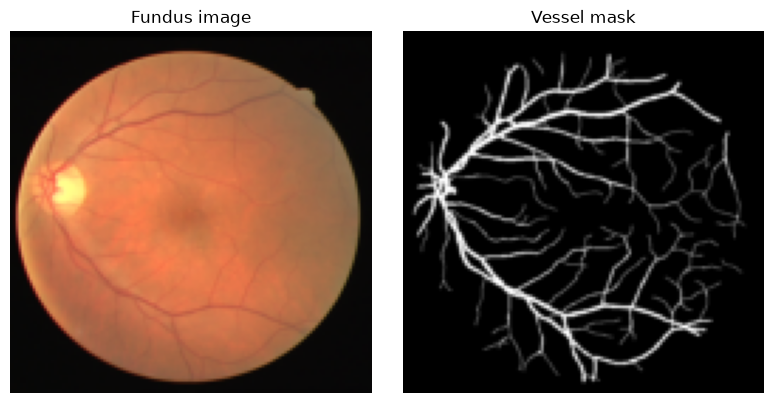

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
X, Y = trainset[0]
# Image: ToTensor gives CHW, imshow wants HWC
axes[0].imshow(X.permute(1, 2, 0).numpy())
axes[0].set_title("Fundus image")
axes[0].axis("off")

# Mask: single channel, use grayscale colormap
axes[1].imshow(Y.squeeze().numpy(), cmap="gray")
axes[1].set_title("Vessel mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

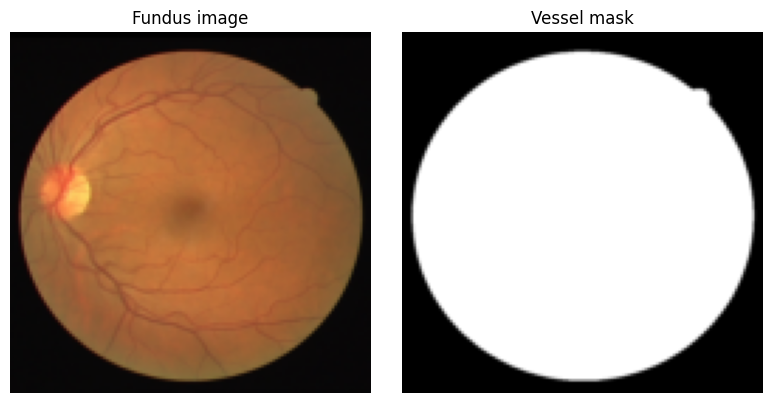

In [4]:
X, Y = testset[0]
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(X.permute(1, 2, 0).numpy())
axes[0].set_title("Fundus image")
axes[0].axis("off")

# Mask: single channel, use grayscale colormap
axes[1].imshow(Y.squeeze().numpy(), cmap="gray")
axes[1].set_title("Vessel mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [4]:
from IDLCV_03.lib.dataset.dataset import PH2

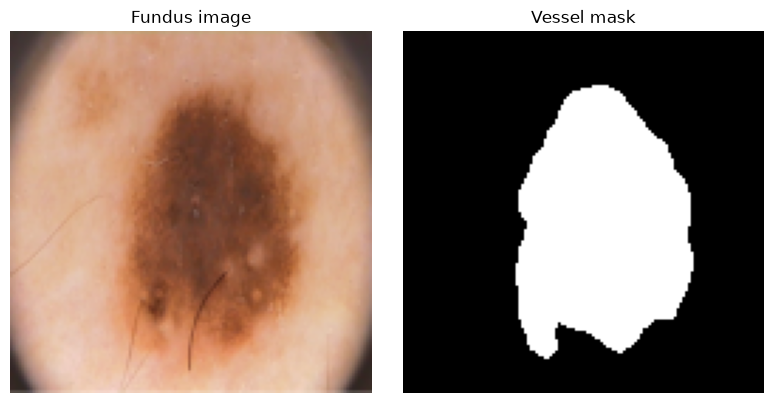

In [5]:
size = 128
train_transform = transforms.Compose([transforms.Resize((size, size)),
                                transforms.ToTensor()])
trainset = PH2(transform=train_transform)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
X, Y = trainset[0]
# Image: ToTensor gives CHW, imshow wants HWC
axes[0].imshow(X.permute(1, 2, 0).numpy())
axes[0].set_title("Fundus image")
axes[0].axis("off")

# Mask: single channel, use grayscale colormap
axes[1].imshow(Y.squeeze().numpy(), cmap="gray")
axes[1].set_title("Vessel mask")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [9]:
%pip install scikit-image

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 88.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 121.0 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [scikit-image] [scikit-image]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Positive candidate at: [88, 68]
Positive candidate at: [70, 52]
Positive candidate at: [87, 41]
Positive candidate at: [94, 81]
Positive candidate at: [92, 80]
Positive candidate at: [90, 74]
Positive candidate at: [65, 61]
Positive candidate at: [41, 75]
Positive candidate at: [39, 69]
Positive candidate at: [81, 99]
Negative candidate at: [36, 44]
Negative candidate at: [80, 124]
Negative candidate at: [31, 47]
Negative candidate at: [14, 37]
Negative candidate at: [33, 36]
Negative candidate at: [40, 23]
Negative candidate at: [15, 5]
Negative candidate at: [113, 111]
Negative candidate at: [35, 3]
Negative candidate at: [82, 119]
Candidates matrix shape: torch.Size([128, 128])
Candidates matrix unique values: tensor([-1,  0,  1], dtype=torch.int32)
Candidates matrix:
tensor([[0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        ...,
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0]], 

(np.float64(-0.5), np.float64(127.5), np.float64(127.5), np.float64(-0.5))

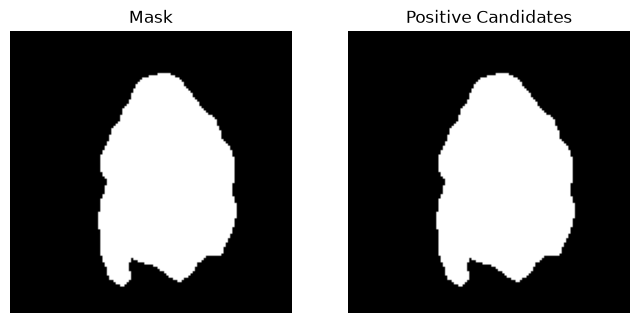

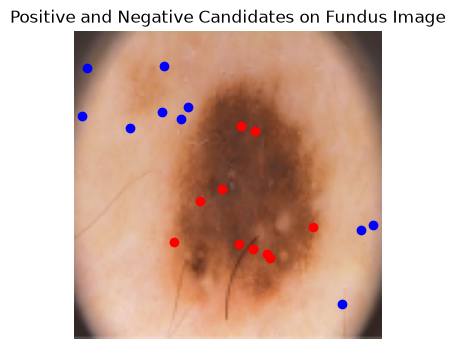

In [67]:
from scipy import ndimage
import torch

mask = Y[0].numpy() > 0

Y_dist = ndimage.distance_transform_edt(mask)

positive_cand = mask  # Keep all vessel pixels

# convert positive_cand to a tensor with 0 and 1 values
positive_cand_tensor = torch.from_numpy(positive_cand.astype(int))

# show image of positive_cand_tensor and mask side by side
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(mask, cmap="gray")
axes[0].set_title("Mask")
axes[0].axis("off")
axes[1].imshow(positive_cand_tensor.numpy(), cmap="gray")
axes[1].set_title("Positive Candidates")
axes[1].axis("off")

# pick 10 random positive candidates and show their coordinates
positive_coords = torch.nonzero(positive_cand_tensor)
generator = torch.Generator().manual_seed(42)
if positive_coords.size(0) > 0:
    weights = torch.from_numpy(Y_dist[positive_cand]).float() ** 0.5
    probs = weights / weights.sum()
    random_indices = torch.multinomial(
        probs,
        min(10, positive_coords.size(0)),
        replacement=False,
        generator=generator,
    )
else:
    random_indices = torch.empty(0, dtype=torch.long)
for idx in random_indices:
    coord = positive_coords[idx]
    print(f"Positive candidate at: {coord.tolist()}")

# pick 10 random negative candidates and show their coordinates
negative_cand = ~mask
negative_cand_tensor = torch.from_numpy(negative_cand.astype(int))
negative_coords = torch.nonzero(negative_cand_tensor)
random_negative_indices = torch.randperm(
    negative_coords.size(0), generator=generator
)[:10]
for idx in random_negative_indices:
    coord = negative_coords[idx]
    print(f"Negative candidate at: {coord.tolist()}")

# put the positive candidates and negative candidates in a single matrix for loss into a 128x128 matrix
candidates_matrix = torch.zeros((128, 128), dtype=torch.int)
for idx in random_indices:
    coord = positive_coords[idx]
    candidates_matrix[coord[0], coord[1]] = 1
for idx in random_negative_indices:
    coord = negative_coords[idx]
    candidates_matrix[coord[0], coord[1]] = -1
# print shape and unique values of candidates_matrix
print(f"Candidates matrix shape: {candidates_matrix.shape}")
print(f"Candidates matrix unique values: {candidates_matrix.unique()}")
print(f"Candidates matrix:\n{candidates_matrix}")


# plot the picked positive candidates and negative candidates on the original image
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(X.permute(1, 2, 0).numpy())
for idx in random_indices:
    coord = positive_coords[idx]
    ax.plot(coord[1], coord[0], 'ro')  # note: x=col, y=row
for idx in random_negative_indices:
    coord = negative_coords[idx]
    ax.plot(coord[1], coord[0], 'bo')  # note: x=col, y=row
ax.set_title("Positive and Negative Candidates on Fundus Image")
ax.axis("off")